# Régression sur le prix des annonces Airbnb à Paris

**Question** : les Jeux olympiques et paralympiques de 2024 ont-ils fait monter le prix des annonces Airbnb situées près des sites de compétition ?

**Démarche :**
1. **Régression sur un relevé** : quels facteurs expliquent le prix, et quel est le lien entre prix et distance au site le plus proche ?
2. **Effet des Jeux dans le temps** : différence de différences sur 2024, puis triple différence 2024 / 2026 pour retirer la saisonnalité des quartiers touristiques.
3. **Test placebo** : la régression de l'étape 1 sur l'été 2026, sans Jeux.

**Sources :**
- Inside Airbnb : relevés mensuels 2024 (stockage de l'équipe) ; relevés publics de juin à septembre 2026 (téléchargés par `telecharger_donnees_externes.py`) ;
- ministère chargé des Sports : sites de compétition, via `sites_competition.py` ;
- INSEE (hôtellerie à Paris) et Eurostat (nuitées via les plateformes en Île-de-France).

**Remarque** : le fichier `listing_16_mars_2024` contient en réalité les données de juin (collectées du 11 au 13 juin). Il est écarté.

## 0. Préparation

On charge les bibliothèques. `statsmodels` sert à estimer les régressions avec des formules proches de celles de R.

In [1]:
from pathlib import Path
from urllib.parse import quote
from urllib.request import urlretrieve
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)

### Relevés Airbnb

Les relevés sont stockés sur le SSP Cloud. Chaque fichier pèse environ 200 Mo : on le télécharge une seule fois dans `donnees_airbnb/` (dossier exclu de git), puis on le relit en local.

On ne garde que les colonnes utiles à l'analyse. Le relevé « mars » est absent du dictionnaire car c'est un doublon de juin.

In [2]:
URL_STOCKAGE = "https://minio.lab.sspcloud.fr/etiennealpy/données paris/"
DOSSIER_AIRBNB = Path("donnees_airbnb")

RELEVES = {
    "janvier": "listing_13_janvier_2024",
    "fevrier": "listing_14_fevrier_2024",
    "avril": "listing_17_avril_2024.csv",
    "mai": "listing_11_mai_2024.csv",
    "juin": "listing_10_juin_2024",
    "juillet": "listing_14_juillet_2024.csv",
    "aout": "listing_09_aout_2024.csv",
    "septembre": "listing_6_septembre_2024",
    "octobre": "listing_07_octobre_2024.csv",
    "novembre": "listing_09_novembre_2024.csv",
    "decembre": "listing_16_decembre_2024",
}

COLONNES = [
    "id", "last_scraped", "latitude", "longitude", "neighbourhood_cleansed",
    "room_type", "accommodates", "bedrooms", "bathrooms", "price",
    "minimum_nights", "number_of_reviews", "review_scores_rating",
    "host_is_superhost", "instant_bookable", "calculated_host_listings_count",
    "availability_30", "number_of_reviews_l30d",
]


def charger_releve(mois):
    """Télécharge le relevé du mois s'il n'est pas déjà en local, puis le lit."""
    nom = RELEVES[mois]
    fichier = DOSSIER_AIRBNB / (nom if nom.endswith(".csv") else nom + ".csv")
    if not fichier.exists():
        DOSSIER_AIRBNB.mkdir(exist_ok=True)
        print(f"Téléchargement de {nom}...")
        urlretrieve(quote(URL_STOCKAGE + nom, safe=":/"), fichier)
    return pd.read_csv(fichier, usecols=COLONNES)

### Sites de compétition

Les sites viennent du script `sites_competition.py` de l'équipe. S'il n'a jamais été lancé, on le lance pour créer le fichier local.

On garde **tous les sites**, olympiques et paralympiques, y compris ceux hors de Paris. Une annonce du 18e arrondissement peut en effet être plus proche du Stade de France (Saint-Denis) que d'un site parisien. Les sites lointains (Marseille, Tahiti…) ne gênent pas : ils ne seront jamais le site le plus proche d'une annonce parisienne.

In [3]:
if not Path("donnees_sites/donnees_nettoyees.csv").exists():
    subprocess.run([sys.executable, "sites_competition.py"], check=True, capture_output=True)

from sites_competition import site_olympiques, site_paralympique

sites = (
    pd.concat([site_olympiques, site_paralympique])
    .dropna(subset=["latitude", "longitude"])
    .drop_duplicates(subset="code_site")
    .reset_index(drop=True)
)
print(f"{len(sites)} sites de compétition distincts")

44 sites de compétition distincts


### Fonctions de distance

On calcule la distance « à vol d'oiseau » sur la sphère terrestre (formule de Haversine), comme dans `prix_en_fonction_de_la_distance.py`.

Le centre de Paris est le point zéro des routes de France, sur le parvis de Notre-Dame.

In [4]:
CENTRE_PARIS = (48.85341, 2.34880)  # point zéro, parvis de Notre-Dame


def distance_km(lat1, lon1, lat2, lon2):
    """Distance de Haversine en km ; accepte des tableaux numpy."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def distance_site_le_plus_proche(annonces, sites):
    """Pour chaque annonce : distance (km) et code du site de compétition le plus proche."""
    # Matrice annonces × sites, puis minimum sur les sites
    d = distance_km(
        annonces["latitude"].to_numpy()[:, None], annonces["longitude"].to_numpy()[:, None],
        sites["latitude"].to_numpy()[None, :], sites["longitude"].to_numpy()[None, :],
    )
    return d.min(axis=1), sites["code_site"].to_numpy()[d.argmin(axis=1)]

### Relevés de l'été 2026

Ces relevés publics d'Inside Airbnb servent de comparaison « sans Jeux ». On utilise seulement **juin à septembre 2026** : les relevés de décembre 2025 à février 2026 n'ont aucun prix, et ceux de mars à mai 2026 ne contiennent qu'environ 39 000 annonces.

**Définition du prix** : en 2026, `price` est le prix par nuit d'un devis pour le premier séjour disponible (en médiane, 6 jours après la collecte). Les relevés 2024 n'ont pas les colonnes de devis, mais la part de prix manquants y est comparable. On suppose donc la même méthode, sans pouvoir le vérifier.

In [5]:
DOSSIER_EXTERNE = Path("donnees_externes/insideairbnb")
RELEVES_2026 = {"juin": "2026-06-16", "juillet": "2026-07-15", "aout": "2026-08-15", "septembre": "2026-09-16"}

if not DOSSIER_EXTERNE.exists():
    subprocess.run([sys.executable, "telecharger_donnees_externes.py"], check=True)


def charger_releve_2026(mois):
    return pd.read_csv(DOSSIER_EXTERNE / f"listings_{RELEVES_2026[mois]}.csv.gz", usecols=COLONNES)

## Contexte : le tourisme à Paris pendant l'été 2024

Avant les régressions, deux séries officielles pour situer l'été des Jeux :
- **INSEE** : taux d'occupation des hôtels parisiens, chaque mois ;
- **Eurostat** : nuitées réservées via Airbnb, Booking et Expedia en Île-de-France, chaque mois.

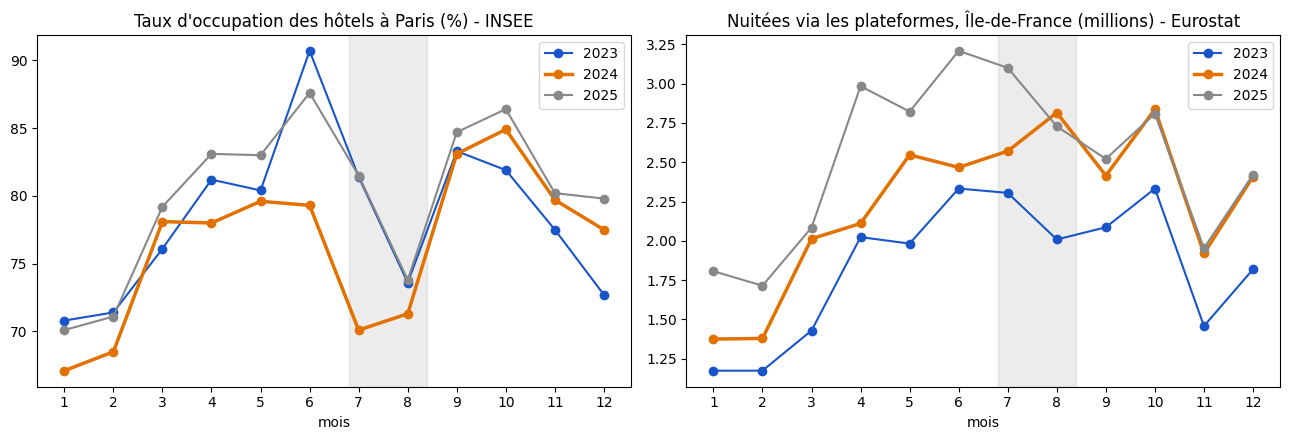

,2023,2024,2025
occupation hôtels (%),,,
juillet,81.4,70.1,81.5
août,73.6,71.3,73.8


In [6]:
import re

xml = Path("donnees_externes/insee_hotellerie_paris.xml").read_text(encoding="utf-8")
series_insee = {}
for attributs, contenu in re.findall(r"<Series ([^>]*)>(.*?)</Series>", xml, re.S):
    titre = re.search(r'TITLE_FR="([^"]*)"', attributs).group(1)
    obs = re.findall(r'TIME_PERIOD="([^"]*)" OBS_VALUE="([^"]*)"', contenu)
    series_insee[titre] = pd.Series({pd.Period(t): float(v) for t, v in obs}).sort_index()
occupation_hotels = next(s for t, s in series_insee.items() if t.startswith("Taux d'occupation"))

eurostat = pd.read_csv("donnees_externes/eurostat_nuitees_plateformes_idf.csv")

ANNEES_CONTEXTE = {2023: "#1855c9", 2024: "#e27100", 2025: "#888888"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for annee, couleur in ANNEES_CONTEXTE.items():
    s = occupation_hotels[occupation_hotels.index.year == annee]
    axes[0].plot(s.index.month, s.values, marker="o", color=couleur, label=annee, linewidth=2.5 if annee == 2024 else 1.5)
    e = eurostat[eurostat["annee"] == annee]
    axes[1].plot(e["mois"], e["nuitees"] / 1e6, marker="o", color=couleur, label=annee, linewidth=2.5 if annee == 2024 else 1.5)
for ax in axes:
    ax.axvspan(6.8, 8.4, color="grey", alpha=0.15)
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("mois")
    ax.legend()
axes[0].set_title("Taux d'occupation des hôtels à Paris (%) - INSEE")
axes[1].set_title("Nuitées via les plateformes, Île-de-France (millions) - Eurostat")
fig.tight_layout()
plt.show()

pd.DataFrame({annee: occupation_hotels[occupation_hotels.index.year == annee].values[6:8] for annee in ANNEES_CONTEXTE},
             index=["juillet", "août"]).rename_axis("occupation hôtels (%)")

**Commentaire** :
- **Hôtels** : l'occupation décroche en juin-juillet 2024 (70,1 % en juillet, contre environ 81,5 % en 2023 et 2025), puis revient à la normale en septembre. Une partie des touristes habituels a évité Paris : c'est un effet d'éviction.
- **Plateformes** : les nuitées augmentent, surtout en août (2,82 millions, contre 2,01 en 2023). Août 2024 est le seul mois où 2024 dépasse 2025, malgré la forte tendance à la hausse de la série.

Les deux secteurs évoluent en sens opposés : la demande s'est déplacée des hôtels vers les locations de courte durée.

## 1. Étape 1 : régression sur un relevé

**Choix retenus :**
- **Relevés** : la même régression sur juin (`listing_10_juin_2024`, collecté du 11 au 13 juin, avant les Jeux) et sur juillet (`listing_14_juillet_2024`, collecté du 15 au 19 juillet, juste avant l'ouverture), pour comparer les deux résultats.
- **Proximité** : tranches de distance au site de compétition le plus proche : moins de 1 km, 1 à 3 km, plus de 3 km (référence).
- **Annonces** : toutes, avec le type de logement (`room_type`) comme variable de contrôle.
- **Emplacement** : effets fixes arrondissement **et** distance au centre de Paris.

### 1.1 Préparation des données

Pour chaque relevé :

1. **Prix** : le texte `"$1,234.00"` devient le nombre 1234. Les annonces sans prix (environ 22 %, souvent inactives) sont retirées.
2. **Prix extrêmes** : on retire les 1 % les moins chers et les 1 % les plus chers. Certaines annonces affichent jusqu'à 90 000 € la nuit, ce qui fausserait les moyennes.
3. **Proximité** : distance au site le plus proche, puis découpage en trois tranches. « Plus de 3 km » sert de référence.
4. **Contrôles** :
   - taille du logement : voyageurs, chambres, salles de bain ;
   - type de logement ;
   - avis : note et nombre d'avis ;
   - hôte : Superhôte, réservation instantanée, nombre minimum de nuits, hôte qui gère plusieurs annonces ;
   - emplacement : arrondissement et distance au centre.
5. **Annonces sans note** (environ un tiers) : on ne les retire pas. On leur attribue la note moyenne et on ajoute une variable `sans_note`, qui vaut 1 pour elles. Le coefficient de `sans_note` mesure l'écart de prix des annonces sans note.

In [7]:
TRANCHES = ["moins de 1 km", "1 à 3 km", "plus de 3 km"]


def preparer(annonces, sites):
    df = annonces.copy()

    # 1. Prix en nombre, annonces sans prix retirées
    df["prix"] = pd.to_numeric(df["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
    n_depart = len(df)
    df = df.dropna(subset=["prix"])

    # 2. Retrait des 1 % de prix les plus bas et les plus hauts
    bas, haut = df["prix"].quantile([0.01, 0.99])
    df = df[df["prix"].between(bas, haut)]
    df["log_prix"] = np.log(df["prix"])

    # 3. Distance au site le plus proche et tranches
    df["dist_site_km"], df["site_proche"] = distance_site_le_plus_proche(df, sites)
    df["tranche"] = pd.cut(df["dist_site_km"], bins=[0, 1, 3, np.inf], labels=TRANCHES, right=False)
    df["dist_centre_km"] = distance_km(df["latitude"], df["longitude"], *CENTRE_PARIS)

    # 4. Variables de contrôle
    df["arrondissement"] = df["neighbourhood_cleansed"]
    df["sans_note"] = df["review_scores_rating"].isna().astype(int)
    df["note"] = df["review_scores_rating"].fillna(df["review_scores_rating"].mean())
    df["log_nb_avis"] = np.log1p(df["number_of_reviews"])
    df["log_nuits_min"] = np.log(df["minimum_nights"].clip(lower=1))
    df["superhote"] = (df["host_is_superhost"] == "t").astype(int)
    df["resa_instantanee"] = (df["instant_bookable"] == "t").astype(int)
    df["hote_multi_annonces"] = (df["calculated_host_listings_count"] > 1).astype(int)

    # Les rares lignes sans chambres ou salles de bain renseignées sont retirées
    df = df.dropna(subset=["bedrooms", "bathrooms"])
    print(f"{n_depart} annonces -> {len(df)} gardées (prix entre {bas:.0f} € et {haut:.0f} €)")
    return df


donnees = {}
for mois in ["juin", "juillet"]:
    print(mois, end=" : ")
    donnees[mois] = preparer(charger_releve(mois), sites)

juin : 

95885 annonces -> 72976 gardées (prix entre 43 € et 2000 €)
juillet : 

98810 annonces -> 75358 gardées (prix entre 42 € et 1853 €)


### 1.2 Premier regard : prix médian par tranche de distance

Avant la régression, on regarde les chiffres bruts : nombre d'annonces et prix médian dans chaque tranche, en juin et en juillet.

In [8]:
resume = pd.concat(
    {mois: df.groupby("tranche", observed=True)["prix"].agg(annonces="size", prix_median="median")
     for mois, df in donnees.items()},
    axis=1,
)
resume

juin              juillet            
              annonces prix_median annonces prix_median
tranche                                                
moins de 1 km    15986       200.0    16606       191.0
1 à 3 km         53277       159.0    54915       150.0
plus de 3 km      3713       120.0     3837       121.0

**Commentaire** : le prix médian passe de 200 € (moins de 1 km) à 120 € (plus de 3 km) en juin, soit +67 %. Mais les annonces proches sont surtout dans les quartiers centraux et touristiques, et la tranche « plus de 3 km » est petite (5 % des annonces, en bordure de Paris). Ces écarts bruts ne mesurent donc pas un effet des Jeux.

### 1.3 Le modèle

$$\log(\text{prix}_i) = \beta_1 \cdot \mathbb{1}[< 1\text{ km}]_i + \beta_2 \cdot \mathbb{1}[1\text{-}3\text{ km}]_i + \gamma \cdot \text{distance au centre}_i + \text{contrôles}_i + \text{effet fixe arrondissement}_i + \varepsilon_i$$

- **Lecture de β₁** : à caractéristiques égales, une annonce à moins de 1 km d'un site coûte environ $(e^{\beta_1} - 1) \times 100$ % de plus qu'une annonce à plus de 3 km, dans le même arrondissement.
- **Erreurs standard robustes (HC1)** : les écarts de prix ne sont pas les mêmes pour tous les logements (un studio et un grand appartement ne varient pas autant). Ces erreurs standard en tiennent compte, pour que les tests restent fiables.
- **Rappel de la limite** : dans un relevé seul, β₁ mesure une **corrélation**. Les sites sont dans des lieux touristiques (tour Eiffel, Concorde…), et une partie de l'écart peut venir de là même sans les Jeux. C'est la comparaison entre mois de l'étape 2 qui isole l'effet des Jeux.

In [9]:
FORMULE = (
    "log_prix ~ C(tranche, Treatment('plus de 3 km'))"
    " + dist_centre_km"
    " + C(room_type) + accommodates + bedrooms + bathrooms"
    " + note + sans_note + log_nb_avis"
    " + superhote + resa_instantanee + log_nuits_min + hote_multi_annonces"
    " + C(arrondissement)"
)

modeles = {mois: smf.ols(FORMULE, data=df).fit(cov_type="HC1") for mois, df in donnees.items()}

for mois, m in modeles.items():
    print(f"{mois} : {int(m.nobs)} annonces, R² = {m.rsquared:.3f}")

juin : 72976 annonces, R² = 0.481
juillet : 75358 annonces, R² = 0.439


### 1.4 Résultats

Tableau des coefficients, sans les effets fixes arrondissement. La colonne « effet en % » traduit le coefficient en écart de prix : $(e^{\beta} - 1) \times 100$.

In [10]:
def tableau(modele):
    t = pd.DataFrame({
        "coef": modele.params,
        "erreur std": modele.bse,
        "p-valeur": modele.pvalues,
        "effet en %": (np.exp(modele.params) - 1) * 100,
    })
    t.loc["Intercept", "effet en %"] = np.nan  # sans interprétation pour la constante
    t = t[~t.index.str.startswith("C(arrondissement)")]
    t.index = (t.index
               .str.replace(r"C\(tranche, Treatment\('plus de 3 km'\)\)\[T\.(.*)\]", r"site à \1", regex=True)
               .str.replace(r"C\(room_type\)\[T\.(.*)\]", r"type : \1", regex=True))
    return t.round(4)


pd.concat({mois: tableau(m) for mois, m in modeles.items()}, axis=1)

juin                                juillet  \
                        coef erreur std p-valeur effet en %    coef   
Intercept             4.1915     0.0405   0.0000        NaN  4.0895   
site à moins de 1 km  0.0527     0.0123   0.0000     5.4099  0.0387   
site à 1 à 3 km       0.0168     0.0104   0.1070     1.6903  0.0020   
type : Hotel room     0.4822     0.0199   0.0000    61.9650  0.2678   
type : Private room  -0.1667     0.0088   0.0000   -15.3564 -0.1909   
type : Shared room   -0.4486     0.0456   0.0000   -36.1506 -0.4040   
dist_centre_km       -0.0936     0.0036   0.0000    -8.9382 -0.0808   
accommodates          0.1354     0.0073   0.0000    14.4951  0.1128   
bedrooms              0.1583     0.0147   0.0000    17.1552  0.1956   
bathrooms             0.0911     0.0301   0.0025     9.5399  0.1116   
note                  0.1503     0.0071   0.0000    16.2218  0.1601   
sans_note             0.2772     0.0062   0.0000    31.9434  0.2176   
log_nb_avis          -0.0278     0.0018   0.0000    -2.7425 -0.0219   
superhote             0.0568     0.0049   0.0000     5.8477  0.0409   
resa_instantanee      0.0100     0.0050   0.0455     1.0013 -0.0592   
log_nuits_min        -0.0957     0.0020   0.0000    -9.1307 -0.0674   
hote_multi_annonces  -0.0763     0.0048   0.0000    -7.3479 -0.1330   

                                                     
                     erreur std p-valeur effet en %  
Intercept                0.0409   0.0000        NaN  
site à moins de 1 km     0.0123   0.0016     3.9510  
site à 1 à 3 km          0.0104   0.8499     0.1979  
type : Hotel room        0.0237   0.0000    30.7032  
type : Private room      0.0086   0.0000   -17.3818  
type : Shared room       0.0493   0.0000   -33.2354  
dist_centre_km           0.0036   0.0000    -7.7605  
accommodates             0.0072   0.0000    11.9366  
bedrooms                 0.0136   0.0000    21.6047  
bathrooms                0.0288   0.0001    11.8081  
note                     0.0071   0.0000    17.3625  
sans_note                0.0063   0.0000    24.3087  
log_nb_avis              0.0017   0.0000    -2.1674  
superhote                0.0049   0.0000     4.1749  
resa_instantanee         0.0049   0.0000    -5.7520  
log_nuits_min            0.0020   0.0000    -6.5212  
hote_multi_annonces      0.0047   0.0000   -12.4568

### 1.5 Juin et juillet côte à côte

Le graphique montre l'écart de prix des deux tranches proches par rapport à « plus de 3 km », avec son intervalle de confiance à 95 %.

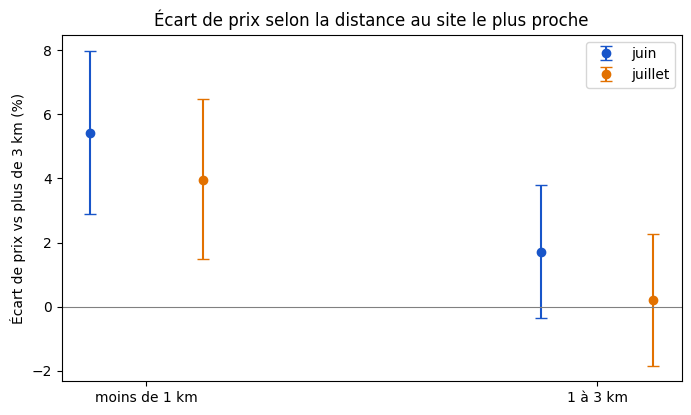

,mois,tranche,effet,bas,haut
0,juin,moins de 1 km,5.4,2.9,8.0
1,juin,1 à 3 km,1.7,-0.4,3.8
2,juillet,moins de 1 km,4.0,1.5,6.5
3,juillet,1 à 3 km,0.2,-1.8,2.3


In [11]:
lignes = []
for mois, m in modeles.items():
    ic = m.conf_int()
    for tranche in ["moins de 1 km", "1 à 3 km"]:
        nom = f"C(tranche, Treatment('plus de 3 km'))[T.{tranche}]"
        lignes.append({
            "mois": mois, "tranche": tranche,
            "effet": (np.exp(m.params[nom]) - 1) * 100,
            "bas": (np.exp(ic.loc[nom, 0]) - 1) * 100,
            "haut": (np.exp(ic.loc[nom, 1]) - 1) * 100,
        })
effets = pd.DataFrame(lignes)

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (mois, couleur) in enumerate([("juin", "#1855c9"), ("juillet", "#e27100")]):
    e = effets[effets["mois"] == mois]
    x = np.arange(len(e)) + (i - 0.5) * 0.25
    ax.errorbar(x, e["effet"], yerr=[e["effet"] - e["bas"], e["haut"] - e["effet"]],
                fmt="o", capsize=4, color=couleur, label=mois)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(range(2), ["moins de 1 km", "1 à 3 km"])
ax.set_ylabel("Écart de prix vs plus de 3 km (%)")
ax.set_title("Écart de prix selon la distance au site le plus proche")
ax.legend()
plt.show()

effets.round(1)

**Commentaire** :
- À caractéristiques égales et dans le même arrondissement, une annonce à moins de 1 km d'un site est **5,4 % plus chère en juin** [2,9 ; 8,0] et **4,0 % en juillet** [1,5 ; 6,5]. Entre 1 et 3 km, l'écart n'est pas significatif.
- L'écart **n'augmente pas** à l'approche des Jeux : les intervalles de juin et juillet se recoupent largement.
- Les contrôles ont le signe attendu : la taille du logement augmente le prix (+12 à 22 % par voyageur, chambre ou salle de bain), les chambres privées sont 15 à 17 % moins chères qu'un logement entier, et chaque kilomètre d'éloignement du centre coûte 8 à 9 %. La note et le statut de Superhôte augmentent le prix, alors que les hôtes multi-annonces sont moins chers. Le modèle explique 44 à 48 % de la variance.

Ces résultats restent une corrélation : il faut suivre les mêmes annonces dans le temps (étape 2).

## 2. Étape 2 : effet des Jeux dans le temps

On suit les mêmes annonces d'un mois à l'autre, en comparant :
- un **groupe proche** : moins de 1 km d'un site (environ 22 % des annonces) ;
- un **groupe témoin** : plus de 2 km (environ 32 %). Le seuil de 3 km laissait trop peu d'annonces (5 %).

On procède en deux temps :
- une **différence de différences sur 2024** ;
- une **triple différence** 2024 / 2026, pour retirer la saisonnalité propre aux quartiers proches des sites.

### 2.1 Panel 2024 : une ligne par annonce et par mois

On empile les 11 relevés de 2024 (pas de mois 3). Les relevés sont collectés aux dates suivantes :
- juillet : du 14 au 28 juillet, juste avant l'ouverture des Jeux le 26 juillet ;
- août : du 9 au 15 août, à la fin des JO ;
- septembre : du 6 au 13 septembre, pendant les Jeux paralympiques.

In [12]:
NUM_MOIS = {
    "janvier": 1, "fevrier": 2, "avril": 4, "mai": 5, "juin": 6, "juillet": 7,
    "aout": 8, "septembre": 9, "octobre": 10, "novembre": 11, "decembre": 12,
}

releves = []
for mois, num in NUM_MOIS.items():
    r = charger_releve(mois)
    r["mois"] = num
    releves.append(r)
panel = pd.concat(releves, ignore_index=True).drop_duplicates(subset=["id", "mois"])

print(f"{len(panel)} lignes, {panel['id'].nunique()} annonces différentes")
panel.groupby("mois").size().rename("annonces en ligne").to_frame().T

1003623 lignes, 125291 annonces différentes


mois,1,2,4,5,6,7,8,9,10,11,12
annonces en ligne,76938,80545,88548,92665,95885,98810,98736,95461,93275,91729,91031


### 2.2 Groupes

Airbnb décale légèrement la position affichée des logements. On fixe donc une position par annonce (la médiane sur l'année), puis on la classe : proche (< 1 km), témoin (> 2 km) ou intermédiaire (retirée).

In [13]:
positions = panel.groupby("id")[["latitude", "longitude"]].median()
positions["dist_site_km"], positions["site_proche"] = distance_site_le_plus_proche(positions, sites)
positions["groupe"] = np.select(
    [positions["dist_site_km"] < 1, positions["dist_site_km"] > 2],
    ["proche", "témoin"],
    default="intermédiaire",
)
positions["groupe"].value_counts().to_frame("annonces")

,annonces
groupe,
intermédiaire,57220
témoin,41122
proche,26949


### 2.3 Variables étudiées

- **`log_prix`** : log du prix, en retirant les 1 % de prix extrêmes de chaque côté, avec des bornes communes à tous les mois.
- **`occupation`** : `1 - availability_30 / 30`, la part des 30 nuits suivantes qui ne sont pas disponibles. Ces nuits sont réservées **ou bloquées par l'hôte**.
- **`avis_30j`** : avis des 30 derniers jours. Ils signalent des séjours effectués.
- **`en_ligne`** : 1 si l'annonce est présente ce mois-là, 0 sinon. On crée une ligne pour chaque annonce et chaque mois.

In [14]:
panel["prix"] = pd.to_numeric(panel["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
bas, haut = panel["prix"].quantile([0.01, 0.99])
panel["log_prix"] = np.log(panel["prix"].where(panel["prix"].between(bas, haut)))
panel["occupation"] = 1 - panel["availability_30"] / 30
panel["avis_30j"] = panel["number_of_reviews_l30d"]
panel["en_ligne"] = 1
print(f"Prix gardés entre {bas:.0f} € et {haut:.0f} €")

# Grille complète annonce × mois (proches et témoins seulement)
ids = positions.index[positions["groupe"] != "intermédiaire"]
grille = pd.MultiIndex.from_product([ids, list(NUM_MOIS.values())], names=["id", "mois"]).to_frame(index=False)
grille = grille.merge(panel[["id", "mois", "prix", "log_prix", "occupation", "avis_30j", "en_ligne"]],
                      on=["id", "mois"], how="left")
grille["en_ligne"] = grille["en_ligne"].fillna(0)
grille = grille.merge(positions[["groupe"]], left_on="id", right_index=True)
grille["proche"] = (grille["groupe"] == "proche").astype(int)
print(f"Grille : {len(grille)} lignes ({len(ids)} annonces × {len(NUM_MOIS)} mois)")

Prix gardés entre 42 € et 1957 €
Grille : 748781 lignes (68071 annonces × 11 mois)


### 2.4 Différence de différences, mois par mois

$$y_{it} = \sum_{m \neq \text{juin}} \delta_m \cdot \text{proche}_i \cdot \mathbb{1}[t = m] + \alpha_i + \lambda_t + \varepsilon_{it}$$

- $\alpha_i$ : effet fixe annonce, qui compare chaque logement à lui-même.
- $\lambda_t$ : effet fixe mois, qui retire ce qui touche tout Paris.
- $\delta_m$ : écart supplémentaire des annonces proches le mois $m$, comparé à juin. Avant juin, il doit être proche de zéro : c'est l'hypothèse des tendances parallèles.
- Les erreurs standard sont regroupées par annonce. Pour le prix, l'écart en % est $(e^{\delta} - 1) \times 100$.

In [15]:
from linearmodels.panel import PanelOLS

VARIABLES = {
    "log_prix": "Prix (log)",
    "occupation": "Occupation (part des 30 nuits suivantes)",
    "avis_30j": "Avis des 30 derniers jours",
    "en_ligne": "Part des annonces en ligne",
}
MOIS_REF = NUM_MOIS["juin"]
AUTRES_MOIS = [m for m in NUM_MOIS.values() if m != MOIS_REF]


def etude_evenement(var):
    """Différence de différences mois par mois, juin en référence."""
    d = grille.dropna(subset=[var]).copy()
    for m in AUTRES_MOIS:
        d[f"proche_x_{m}"] = d["proche"] * (d["mois"] == m)
    d = d.set_index(["id", "mois"])
    exog = d[[f"proche_x_{m}" for m in AUTRES_MOIS]]
    return PanelOLS(d[var], exog, entity_effects=True, time_effects=True).fit(
        cov_type="clustered", cluster_entity=True
    )


resultats = {var: etude_evenement(var) for var in VARIABLES}
for var, r in resultats.items():
    print(f"{var:12s} : {int(r.nobs)} observations, {r.entity_info['total']:.0f} annonces")

log_prix     : 382169 observations, 57798 annonces
occupation   : 544701 observations, 68071 annonces
avis_30j     : 544701 observations, 68071 annonces
en_ligne     : 748781 observations, 68071 annonces


### 2.5 Résultats

Chaque point est l'écart supplémentaire des annonces proches par rapport aux témoins, comparé à juin, avec son intervalle de confiance à 95 %. Il est exprimé en % pour le prix, en points de % pour l'occupation et la présence en ligne, et en nombre d'avis pour les avis.

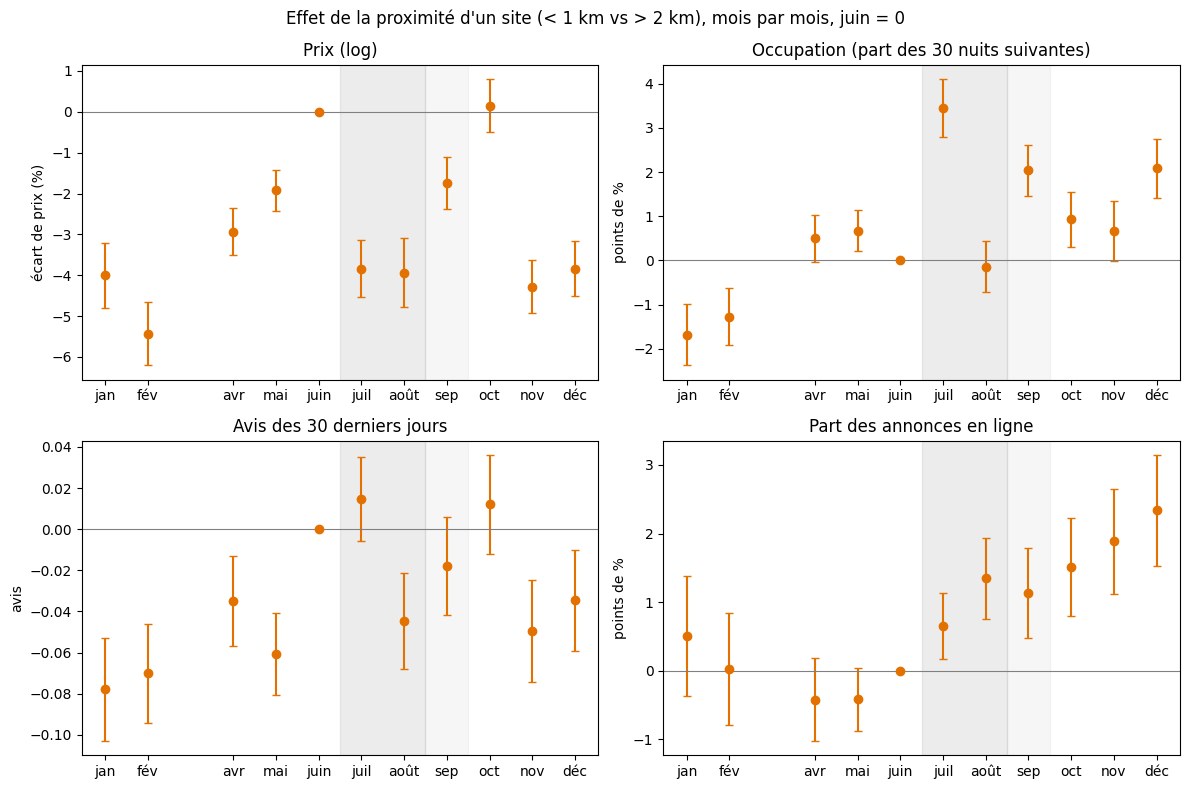

log_prix                        occupation                         \
        effet    bas   haut p-valeur      effet    bas   haut p-valeur   
mois                                                                     
1      -4.006 -4.802 -3.203    0.000     -1.678 -2.371 -0.985    0.000   
2      -5.437 -6.202 -4.666    0.000     -1.278 -1.923 -0.633    0.000   
4      -2.935 -3.514 -2.353    0.000      0.499 -0.030  1.028    0.065   
5      -1.925 -2.419 -1.428    0.000      0.673  0.213  1.132    0.004   
6       0.000  0.000  0.000      NaN      0.000  0.000  0.000      NaN   
7      -3.842 -4.536 -3.143    0.000      3.448  2.792  4.104    0.000   
8      -3.940 -4.787 -3.086    0.000     -0.143 -0.723  0.436    0.628   
9      -1.749 -2.386 -1.108    0.000      2.036  1.457  2.615    0.000   
10      0.154 -0.488  0.799    0.639      0.932  0.314  1.550    0.003   
11     -4.279 -4.924 -3.630    0.000      0.670 -0.003  1.342    0.051   
12     -3.835 -4.500 -3.166    0.000      2.091  1.423  2.758    0.000   

     avis_30j                        en_ligne                         
        effet    bas   haut p-valeur    effet    bas   haut p-valeur  
mois                                                                  
1      -0.078 -0.103 -0.053    0.000    0.509 -0.366  1.385    0.254  
2      -0.070 -0.094 -0.046    0.000    0.025 -0.795  0.845    0.953  
4      -0.035 -0.057 -0.013    0.002   -0.422 -1.023  0.180    0.169  
5      -0.061 -0.081 -0.041    0.000   -0.415 -0.875  0.044    0.077  
6       0.000  0.000  0.000      NaN    0.000  0.000  0.000      NaN  
7       0.015 -0.006  0.035    0.153    0.651  0.170  1.133    0.008  
8      -0.045 -0.068 -0.021    0.000    1.351  0.761  1.941    0.000  
9      -0.018 -0.042  0.006    0.137    1.128  0.473  1.783    0.001  
10      0.012 -0.012  0.036    0.326    1.515  0.803  2.227    0.000  
11     -0.049 -0.074 -0.025    0.000    1.886  1.119  2.653    0.000  
12     -0.035 -0.059 -0.010    0.005    2.339  1.533  3.145    0.000

In [16]:
ETIQUETTES_MOIS = ["jan", "fév", "avr", "mai", "juin", "juil", "août", "sep", "oct", "nov", "déc"]


def zones_jeux(ax):
    """Grise la période des Jeux olympiques (juillet-août) et paralympiques (septembre)."""
    ax.axvspan(6.5, 8.5, color="grey", alpha=0.15, label="JO")
    ax.axvspan(8.5, 9.5, color="grey", alpha=0.07, label="JOP")
    ax.set_xticks(list(NUM_MOIS.values()), ETIQUETTES_MOIS)


def mise_a_echelle(var, x):
    if var == "log_prix":
        return (np.exp(x) - 1) * 100
    if var in ("occupation", "en_ligne"):
        return x * 100
    return x


UNITES = {"log_prix": "écart de prix (%)", "occupation": "points de %",
          "avis_30j": "avis", "en_ligne": "points de %"}

tableaux = {}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (var, r) in zip(axes.flat, resultats.items()):
    ic = r.conf_int()
    t = pd.DataFrame({
        "mois": AUTRES_MOIS,
        "effet": mise_a_echelle(var, r.params.to_numpy()),
        "bas": mise_a_echelle(var, ic["lower"].to_numpy()),
        "haut": mise_a_echelle(var, ic["upper"].to_numpy()),
        "p-valeur": r.pvalues.to_numpy(),
    })
    t = pd.concat([t, pd.DataFrame({"mois": [MOIS_REF], "effet": [0.0], "bas": [0.0], "haut": [0.0]})]).sort_values("mois")
    tableaux[var] = t.set_index("mois")
    ax.errorbar(t["mois"], t["effet"], yerr=[t["effet"] - t["bas"], t["haut"] - t["effet"]],
                fmt="o", capsize=3, color="#e27100")
    ax.axhline(0, color="grey", linewidth=0.8)
    zones_jeux(ax)
    ax.set_title(VARIABLES[var])
    ax.set_ylabel(UNITES[var])
fig.suptitle("Effet de la proximité d'un site (< 1 km vs > 2 km), mois par mois, juin = 0")
fig.tight_layout()
plt.show()

pd.concat(tableaux, axis=1).round(3)

**Commentaire** :
- **Avant juin**, les effets sur le prix ne sont pas nuls (−4 à −5 % en janvier-février, −2 % en mai) : l'hypothèse des tendances parallèles est **rejetée pour le prix**. Elle tient pour la présence en ligne.
- **Prix en juillet-août** : les annonces proches sont relativement moins chères qu'en juin (−3,8 %). On retrouve des valeurs semblables en novembre-décembre : juin est un pic propre aux quartiers touristiques, pas un effet des Jeux.
- **Occupation** : +3,4 points en juillet et +2,0 en septembre, mais les effets restent positifs après les Jeux.
- **Présence en ligne** : l'effet augmente régulièrement jusqu'en décembre. C'est une tendance de fond, pas des annonces créées pour les Jeux.

Avec 2024 seule, on ne peut pas séparer les Jeux de la saisonnalité : il faut une année sans Jeux.

### 2.6 Triple différence : l'été 2024 comparé à l'été 2026

On compare les relevés de juin à septembre 2024 aux mêmes mois de 2026, sans Jeux. On garde les mêmes groupes.

$$y_{it} = \sum_{m \in \{7,8,9\}} \Big[\gamma_m \cdot \text{proche}_i \cdot \mathbb{1}[\text{mois}=m] + \delta_m \cdot \text{proche}_i \cdot \mathbb{1}[\text{mois}=m] \cdot \mathbb{1}[2024]\Big] + \alpha_{i,\text{année}} + \lambda_t + \varepsilon_{it}$$

- $\alpha_{i,\text{année}}$ : effet fixe annonce × année. $\lambda_t$ : effet fixe mois de chaque année.
- $\gamma_m$ : écart saisonnier habituel entre proches et témoins, par rapport à juin.
- **$\delta_m$ : effet des Jeux**, c'est-à-dire ce que 2024 a de plus que 2026.

**Hypothèse** : sans les Jeux, la saisonnalité aurait été la même en 2024 et en 2026. **Limite** : si juin 2024 était déjà touché par les Jeux, l'effet est sous-estimé.

In [17]:
MOIS_ETE = {"juin": 6, "juillet": 7, "aout": 8, "septembre": 9}

morceaux = []
for annee, charger in [(2024, charger_releve), (2026, charger_releve_2026)]:
    for mois, num in MOIS_ETE.items():
        r = charger(mois)
        r["annee"], r["mois"] = annee, num
        morceaux.append(r)
ete = pd.concat(morceaux, ignore_index=True).drop_duplicates(subset=["id", "annee", "mois"])

# Position fixe par annonce, puis groupes proche / témoin
pos_ete = ete.groupby("id")[["latitude", "longitude"]].median()
pos_ete["dist_site_km"], _ = distance_site_le_plus_proche(pos_ete, sites)
pos_ete["groupe"] = np.select([pos_ete["dist_site_km"] < 1, pos_ete["dist_site_km"] > 2],
                              ["proche", "témoin"], default="intermédiaire")
ete = ete.merge(pos_ete[["groupe"]], left_on="id", right_index=True)
ete = ete[ete["groupe"] != "intermédiaire"].copy()
ete["proche"] = (ete["groupe"] == "proche").astype(int)

# Variables : prix extrêmes retirés avec des bornes propres à chaque année
ete["prix"] = pd.to_numeric(ete["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
bornes = ete.groupby("annee")["prix"].quantile([0.01, 0.99]).unstack()
dans_bornes = ete["prix"].between(ete["annee"].map(bornes[0.01]), ete["annee"].map(bornes[0.99]))
ete["log_prix"] = np.log(ete["prix"].where(dans_bornes))
ete["occupation"] = 1 - ete["availability_30"] / 30
ete["avis_30j"] = ete["number_of_reviews_l30d"]

ete.groupby(["annee", "groupe"])["id"].nunique().unstack().rename_axis(None, axis=1)

,proche,témoin
annee,,
2024,22915,35544
2026,18640,26674


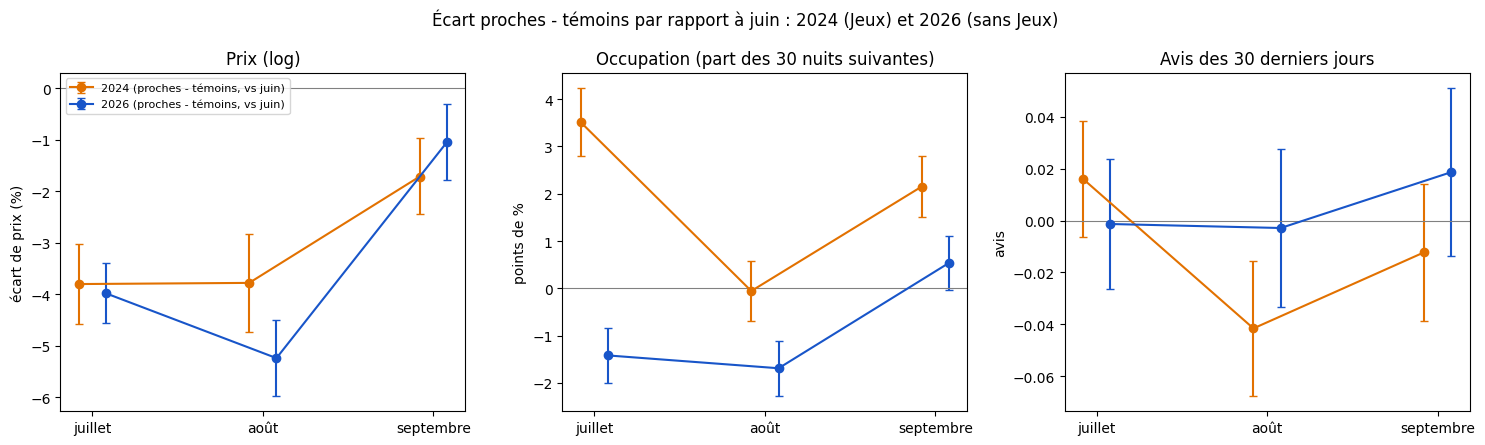

effet des Jeux  \
Prix (log)                               juillet             0.188   
                                         août                1.542   
                                         septembre          -0.676   
Occupation (part des 30 nuits suivantes) juillet             4.926   
                                         août                1.632   
                                         septembre           1.613   
Avis des 30 derniers jours               juillet             0.017   
                                         août               -0.039   
                                         septembre          -0.031   

                                                    bas IC 95 %  haut IC 95 %  \
Prix (log)                               juillet         -0.790         1.175   
                                         août             0.306         2.793   
                                         septembre       -1.721         0.381   
Occupation (part des 30 nuits suivantes) juillet          4.015         5.838   
                                         août             0.786         2.478   
                                         septembre        0.765         2.461   
Avis des 30 derniers jours               juillet         -0.016         0.050   
                                         août            -0.077        -0.001   
                                         septembre       -0.071         0.009   

                                                    p-valeur  
Prix (log)                               juillet       0.708  
                                         août          0.014  
                                         septembre     0.209  
Occupation (part des 30 nuits suivantes) juillet       0.000  
                                         août          0.000  
                                         septembre     0.000  
Avis des 30 derniers jours               juillet       0.302  
                                         août          0.046  
                                         septembre     0.130

In [18]:
VARIABLES_ETE = {k: v for k, v in VARIABLES.items() if k != "en_ligne"}


def triple_difference(var):
    d = ete.dropna(subset=[var]).copy()
    d["annonce_annee"] = pd.factorize(d["id"].astype(str) + "_" + d["annee"].astype(str))[0]
    d["periode"] = d["annee"] * 100 + d["mois"]
    d["cluster"] = pd.factorize(d["id"])[0]
    noms = []
    for m in [7, 8, 9]:
        d[f"proche × {m}"] = d["proche"] * (d["mois"] == m)
        d[f"proche × {m} × 2024"] = d[f"proche × {m}"] * (d["annee"] == 2024)
        noms += [f"proche × {m}", f"proche × {m} × 2024"]
    d = d.set_index(["annonce_annee", "periode"])
    return PanelOLS(d[var], d[noms], entity_effects=True, time_effects=True).fit(
        cov_type="clustered", clusters=d[["cluster"]])


def par_annee(var, annee):
    """Écart proches - témoins par rapport à juin, pour une seule année."""
    d = ete[(ete["annee"] == annee)].dropna(subset=[var]).copy()
    for m in [7, 8, 9]:
        d[f"proche × {m}"] = d["proche"] * (d["mois"] == m)
    d = d.set_index(["id", "mois"])
    return PanelOLS(d[var], d[[f"proche × {m}" for m in [7, 8, 9]]],
                    entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True)


NOMS_MOIS = {7: "juillet", 8: "août", 9: "septembre"}
resultats_td = {var: triple_difference(var) for var in VARIABLES_ETE}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
tableau_td = {}
for ax, var in zip(axes, VARIABLES_ETE):
    for annee, couleur in [(2024, "#e27100"), (2026, "#1855c9")]:
        r = par_annee(var, annee)
        effet = mise_a_echelle(var, r.params.to_numpy())
        ic = r.conf_int()
        ax.errorbar(np.array([7, 8, 9]) + (0.08 if annee == 2026 else -0.08), effet,
                    yerr=[effet - mise_a_echelle(var, ic["lower"].to_numpy()),
                          mise_a_echelle(var, ic["upper"].to_numpy()) - effet],
                    fmt="o-", capsize=3, color=couleur, label=f"{annee} (proches - témoins, vs juin)")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xticks([7, 8, 9], ["juillet", "août", "septembre"])
    ax.set_title(VARIABLES[var])
    ax.set_ylabel(UNITES[var])
    r = resultats_td[var]
    noms = [f"proche × {m} × 2024" for m in [7, 8, 9]]
    tableau_td[VARIABLES[var]] = pd.DataFrame({
        "effet des Jeux": mise_a_echelle(var, r.params[noms]).to_numpy(),
        "bas IC 95 %": mise_a_echelle(var, r.conf_int().loc[noms, "lower"]).to_numpy(),
        "haut IC 95 %": mise_a_echelle(var, r.conf_int().loc[noms, "upper"]).to_numpy(),
        "p-valeur": r.pvalues[noms].to_numpy(),
    }, index=[NOMS_MOIS[m] for m in [7, 8, 9]])
axes[0].legend(fontsize=8)
fig.suptitle("Écart proches - témoins par rapport à juin : 2024 (Jeux) et 2026 (sans Jeux)")
fig.tight_layout()
plt.show()

pd.concat(tableau_td).round(3)

Le tableau donne **l'effet des Jeux** ($\delta_m$), c'est-à-dire l'écart entre les deux courbes.

**Commentaire** :
- **En 2026, sans Jeux**, les annonces proches sont aussi relativement moins chères en juillet-août qu'en juin (−4 à −5 %). C'est la saisonnalité qui biaisait la section 2.5.
- **Une fois cette saisonnalité retirée** :
  - **Prix** : +0,2 % en juillet (non significatif), **+1,5 % en août** [0,3 ; 2,8], −0,7 % en septembre (non significatif).
  - **Occupation** : **+4,9 points en juillet** [4,0 ; 5,8] (nuits des JO), +1,6 point en août et en septembre.
  - **Avis** : aucun effet net.

Les annonces proches ont été **plus réservées** pendant les Jeux, mais leurs **prix ont à peine augmenté**.

## 3. Test placebo : la régression de l'étape 1 sur l'été 2026

À l'étape 1, les annonces à moins de 1 km d'un site sont 4 à 5 % plus chères, à caractéristiques égales. Cet écart vient-il des Jeux ou simplement de l'emplacement touristique ?

**Le test** : on refait exactement la même régression en juin et juillet 2026, sans Jeux.
- Si l'écart est le même en 2026, il vient de l'emplacement.
- S'il disparaît en 2026, il était lié aux Jeux.

On utilise les mêmes sites et les mêmes tranches de distance. En 2026, une partie des annonces avec prix n'indiquent pas le nombre de chambres ou de salles de bain (environ 15 %) : elles sont retirées, comme en 2024.

In [19]:
donnees_2026 = {}
for mois in ["juin", "juillet"]:
    print(mois, "2026", end=" : ")
    donnees_2026[mois] = preparer(charger_releve_2026(mois), sites)

modeles_2026 = {mois: smf.ols(FORMULE, data=df).fit(cov_type="HC1") for mois, df in donnees_2026.items()}


def effets_tranches(modele):
    ic = modele.conf_int()
    lignes = []
    for tranche in ["moins de 1 km", "1 à 3 km"]:
        nom = f"C(tranche, Treatment('plus de 3 km'))[T.{tranche}]"
        lignes.append({"tranche": tranche,
                       "effet (%)": (np.exp(modele.params[nom]) - 1) * 100,
                       "bas": (np.exp(ic.loc[nom, 0]) - 1) * 100,
                       "haut": (np.exp(ic.loc[nom, 1]) - 1) * 100})
    return pd.DataFrame(lignes).set_index("tranche")


comparaison = pd.concat({
    "juin 2024": effets_tranches(modeles["juin"]),
    "juillet 2024": effets_tranches(modeles["juillet"]),
    "juin 2026": effets_tranches(modeles_2026["juin"]),
    "juillet 2026": effets_tranches(modeles_2026["juillet"]),
})
comparaison.round(1)

juin 2026 : 

77679 annonces -> 35695 gardées (prix entre 30 € et 1875 €)
juillet 2026 : 

78071 annonces -> 36162 gardées (prix entre 33 € et 1735 €)


effet (%)  bas  haut
             tranche                            
juin 2024    moins de 1 km        5.4  2.9   8.0
             1 à 3 km             1.7 -0.4   3.8
juillet 2024 moins de 1 km        4.0  1.5   6.5
             1 à 3 km             0.2 -1.8   2.3
juin 2026    moins de 1 km        6.0  2.7   9.4
             1 à 3 km             1.2 -1.5   4.0
juillet 2026 moins de 1 km        4.0  0.8   7.2
             1 à 3 km            -0.1 -2.7   2.5

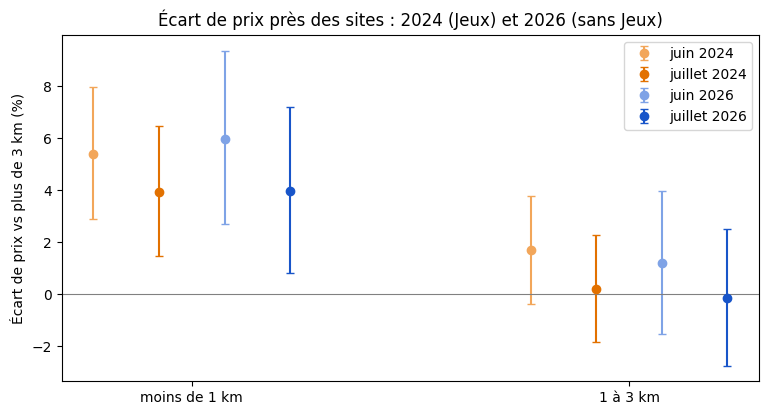

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
couleurs = {"juin 2024": "#f2a65a", "juillet 2024": "#e27100", "juin 2026": "#7fa3e6", "juillet 2026": "#1855c9"}
for i, (releve, couleur) in enumerate(couleurs.items()):
    e = comparaison.loc[releve]
    x = np.arange(len(e)) + (i - 1.5) * 0.15
    ax.errorbar(x, e["effet (%)"], yerr=[e["effet (%)"] - e["bas"], e["haut"] - e["effet (%)"]],
                fmt="o", capsize=3, color=couleur, label=releve)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(range(2), ["moins de 1 km", "1 à 3 km"])
ax.set_ylabel("Écart de prix vs plus de 3 km (%)")
ax.set_title("Écart de prix près des sites : 2024 (Jeux) et 2026 (sans Jeux)")
ax.legend()
plt.show()

### 3.1 La distance en continu

Au lieu de trois tranches, on découpe la distance en **tranches de 250 m**, jusqu'à 2,5 km. La référence est « plus de 2,5 km » (environ 12 % des annonces), plus fournie que « plus de 3 km ». On obtient une courbe de l'écart de prix en fonction de la distance, pour chaque relevé : elle montre **à quelle distance la prime disparaît**, sans fixer de seuil à l'avance.

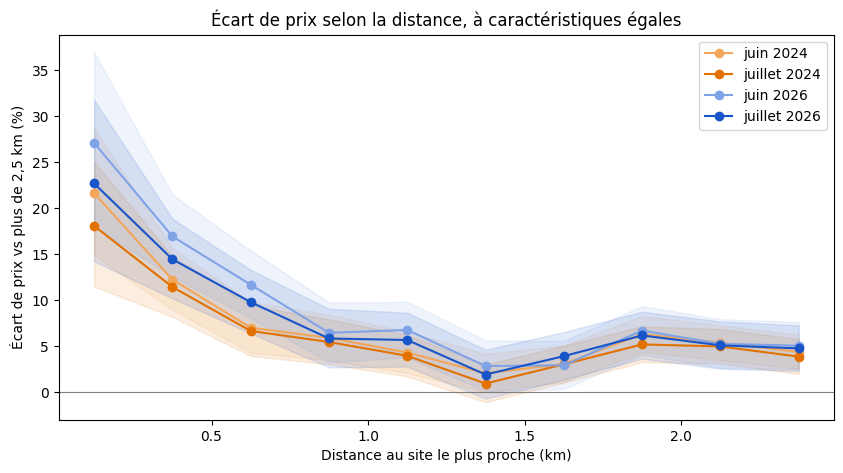

,juin 2024,juillet 2024,juin 2026,juillet 2026
distance (km),,,,
0.125,21.6,18.1,27.1,22.7
0.375,12.3,11.5,16.9,14.5
0.625,7.0,6.7,11.7,9.8
0.875,5.9,5.5,6.5,5.9
1.125,4.3,4.0,6.8,5.7
1.375,2.1,1.0,2.9,1.9
1.625,3.1,3.1,3.0,3.9
1.875,6.3,5.2,6.7,6.2
2.125,5.4,5.0,5.3,5.1


In [21]:
BORNES_FINES = list(np.arange(0, 2.51, 0.25)) + [np.inf]
ETIQUETTES_FINES = [f"{a:.2f}-{b:.2f} km" for a, b in zip(BORNES_FINES[:-2], BORNES_FINES[1:-1])] + ["plus de 2,5 km"]
FORMULE_FINE = FORMULE.replace("C(tranche, Treatment('plus de 3 km'))", "C(tranche_fine, Treatment('plus de 2,5 km'))")


def courbe_distance(df):
    df = df.copy()
    df["tranche_fine"] = pd.cut(df["dist_site_km"], bins=BORNES_FINES, labels=ETIQUETTES_FINES, right=False)
    m = smf.ols(FORMULE_FINE, data=df).fit(cov_type="HC1")
    ic = m.conf_int()
    lignes = []
    for a, etiquette in zip(BORNES_FINES[:-2], ETIQUETTES_FINES[:-1]):
        nom = f"C(tranche_fine, Treatment('plus de 2,5 km'))[T.{etiquette}]"
        lignes.append({"distance (km)": a + 0.125,
                       "effet (%)": (np.exp(m.params[nom]) - 1) * 100,
                       "bas": (np.exp(ic.loc[nom, 0]) - 1) * 100,
                       "haut": (np.exp(ic.loc[nom, 1]) - 1) * 100})
    return pd.DataFrame(lignes).set_index("distance (km)")


releves_courbe = {"juin 2024": donnees["juin"], "juillet 2024": donnees["juillet"],
                  "juin 2026": donnees_2026["juin"], "juillet 2026": donnees_2026["juillet"]}
courbes = {nom: courbe_distance(df) for nom, df in releves_courbe.items()}

fig, ax = plt.subplots(figsize=(10, 5))
for nom, c in courbes.items():
    ax.plot(c.index, c["effet (%)"], marker="o", color=couleurs[nom], label=nom)
    ax.fill_between(c.index, c["bas"], c["haut"], color=couleurs[nom], alpha=0.12)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Distance au site le plus proche (km)")
ax.set_ylabel("Écart de prix vs plus de 2,5 km (%)")
ax.set_title("Écart de prix selon la distance, à caractéristiques égales")
ax.legend()
plt.show()

pd.concat({nom: c["effet (%)"] for nom, c in courbes.items()}, axis=1).round(1)

**Commentaire** :
- La prime à moins de 1 km est la même en 2026 sans Jeux (+6,0 % en juin, +4,0 % en juillet) qu'en 2024 (+5,4 %, +4,0 %).
- La courbe en distance a la même forme pour les quatre relevés : environ +20 % à moins de 250 m, puis 2 à 7 % au-delà de 1 km. Juillet 2024 ne se détache pas.
- La prime de l'étape 1 vient donc de **l'emplacement** (Tour Eiffel, Concorde, Invalides…), pas des Jeux.

Limite : les relevés 2026 ont environ deux fois moins d'annonces avec un prix.

## 4. Conclusion

Les Jeux ont **très peu fait monter les prix** près des sites :
1. La prime de 4 à 5 % près des sites existe aussi en 2026 : elle vient de l'emplacement (étape 1 et test placebo).
2. Sur 2024 seule, la différence de différences est faussée par la saisonnalité des quartiers touristiques. Une fois celle-ci retirée grâce à 2026, l'effet sur le prix est nul en juillet et en septembre, et d'environ +1,5 % en août.
3. L'effet porte surtout sur les **réservations** : +4,9 points d'occupation pour les nuits des JO, alors que les hôtels se vidaient en juillet.

Les Jeux ont donc surtout **déplacé la demande** vers les locations de courte durée, sans flambée des prix près des sites.

**Limites** : 2026 est deux ans plus tard ; le prix observé est le prix affiché, pas le prix payé.